# Optimize PIV for 10-minute data frames (vis, [Baja movie](https://github.com/brianmapes/stratocu_waves/blob/main/DATA/Baja_202307051401-202307052331_g18_conus_band2_vonkarmans-waves_nolabels.gif)) 

## Multipass OpenPIV: coarse to fine refinement 
#### [Claude explanation here](https://claude.ai/artifact/XnLkasiro2YcTXMJ7zNj8G#144eb714-5607)

In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from openpiv import pyprocess, validation, filters, piv
import scipy.signal
from scipy.ndimage import gaussian_filter as smoo 
from scipy import ndimage as ndi
from matplotlib.animation import FuncAnimation, writers
from matplotlib import animation
from IPython.display import display, HTML
from matplotlib.animation import PillowWriter
from pathlib import Path

In [54]:
# Open a multi-time xarray dataset 

import glob
from datetime import datetime
import os

# 1. Define the file pattern
#file_pattern = '/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/IR/Data/IR_2023_10_12*.nc'
file_pattern = '/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/Hanna_outputs/Baja/Files/*.nc'

files = sorted(glob.glob(file_pattern))

# Sort by time, just to be sure it is in order 
ds_combined = xr.open_mfdataset(files)

ds = ds_combined
ds

<xarray.Dataset> Size: 456MB
Dimensions:  (time: 55, lat: 1080, lon: 1920)
Coordinates:
  * time     (time) datetime64[ns] 440B 2023-07-05T14:16:00 ... 2023-07-05T23...
  * lat      (lat) float32 4kB 26.89 26.89 26.89 26.9 ... 30.34 30.34 30.35
  * lon      (lon) float32 8kB -121.3 -121.3 -121.3 ... -114.8 -114.8 -114.8
Data variables:
    Tb       (time, lat, lon) float32 456MB dask.array<chunksize=(1, 1080, 1920), meta=np.ndarray>
Attributes:
    title:           Baja California GOES-18 band 2 loop converted from anima...
    source_gif:      Baja_202307051401-202307052331_g18_conus_band2_vonkarman...
    georeferencing:  approximate: linear lat(y), lon(x) fit to island tie points
    time_inference:  5-min base cadence; dropped frames detected from image c...
    frame_time_utc:  2023-07-05T14:16:00Z

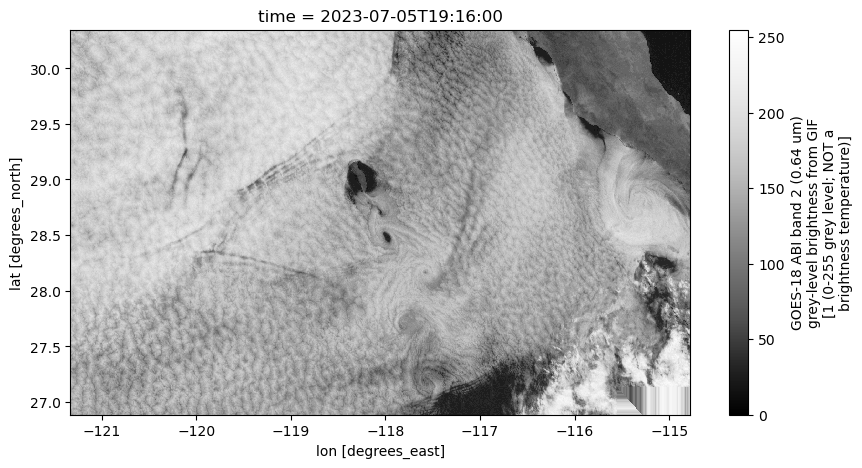

In [55]:
ds.Tb[30].plot(size=5,aspect=2, cmap='Greys_r');

In [5]:
# Define smooth_xarray and hipass_xarray functions 

def smooth_xarray(raw, sigma=5):
    # Smooth the values and replace into a DataArray using the original object's metadata
    smoothed_values = smoo(raw, 5, axes=(raw.get_axis_num('lat'), raw.get_axis_num('lon')))
    da_smooth = xr.DataArray(smoothed_values, dims=raw.dims,coords=raw.coords,attrs=raw.attrs,name=raw.name)

    return da_smooth

def hipass_xarray(raw, sigma=5):
    # Subtract smoothed & replace into a DataArray using the original object's metadata
    return raw - smooth_xarray(raw, sigma)


In [56]:
# High pass (subtract smoothed array): not doing this anymore, multipass PIV is much better
# hipass_xarray(ds.Tb[30], sigma=5).plot(size=5,aspect=2, cmap='RdBu_r', vmin=-20,vmax=20);

In [57]:
# Grab an image pair for processing, frame_a, frame_b
#hp1 = hipass_xarray( ds.Tb[30] )
#hp2 = hipass_xarray( ds.Tb[31] )

frame_a = ( ds.Tb[30] )
frame_b = ( ds.Tb[31] )

# Do PIV on two high passed frames 
### Claude wrote this xarray wrapper, piv_to_xarray
Units — m/s

In [43]:
# NEW multipass piv_to_xarray 
# OpenPIV (0.26.1) multipass window-deformation PIV -> georeferenced xarray Dataset
# All correlation, deformation, validation and outlier replacement is OpenPIV's own code
# (the same steps as openpiv.windef.simple_multipass). This wrapper only:
#   - fills NaNs in the images, builds PIVSettings from your arguments,
#   - keeps results in image coordinates (skips windef.transform_coordinates, whose flipped y
#     is easy to misalign with the u, v arrays),
#   - converts pixel displacements to m/s using the frames' own lat/lon coordinates.
# Image convention (verified in CELL 2): u_img = +column direction, v_img = +row direction.
# ==============================================================================================
import contextlib
import io
import numpy as np
import xarray as xr
from scipy.ndimage import map_coordinates
from openpiv import windef, validation, filters

M_PER_DEG = 111_320.0


def make_settings(windowsizes=(128, 64, 32, 32), overlaps=(64, 32, 16, 16), max_disp_px=40, **overrides):
    """
    PIVSettings with explicit choices; any other PIVSettings field can be overridden by name.
    Default repeats the final 32-px pass: each pass removes about half of the remaining
    sub-pixel bias toward zero displacement (see the bias check in CELL 2).
    """
    s = windef.PIVSettings()
    s.windowsizes = tuple(windowsizes)
    s.overlap = tuple(overlaps)
    s.num_iterations = len(windowsizes)
    # global displacement limits: the default (-30, 30) px would reject your fastest winds
    s.min_max_u_disp = (-max_disp_px, max_disp_px)
    s.min_max_v_disp = (-max_disp_px, max_disp_px)
    s.show_all_plots = False
    for k, v in overrides.items():
        if not hasattr(s, k):
            raise AttributeError(f"PIVSettings has no field '{k}'")
        setattr(s, k, v)
    return s

from scipy.interpolate import RectBivariateSpline
def openpiv_pixels(img_a, img_b, settings, quiet=True, ref_pass=None, max_dev_px=None):
    """
    Run OpenPIV multipass. Returns window centres (x = column, y = row), u_img, v_img (px/frame), flags.
    ref_pass, max_dev_px : optional large-scale consistency check. After the final pass, any vector
        that differs by more than max_dev_px from the coarser pass number ref_pass (0 = first pass)
        is flagged and replaced by that coarser estimate.
    """
    a = np.array(img_a, dtype=np.float64)
    b = np.array(img_b, dtype=np.float64)
    for im in (a, b):                                   # OpenPIV's FFTs cannot handle NaN
        bad = ~np.isfinite(im)
        if bad.any():
            im[bad] = np.nanmean(im)
    ref = None
    with contextlib.redirect_stdout(io.StringIO()) if quiet else contextlib.nullcontext():
        x, y, u, v, s2n = windef.first_pass(a, b, settings)
        u = np.ma.array(u, mask=np.zeros_like(u, bool))
        v = np.ma.array(v, mask=np.zeros_like(v, bool))
        flags = validation.typical_validation(u, v, s2n, settings)
        u, v = filters.replace_outliers(u, v, flags, method=settings.filter_method,
                                        max_iter=settings.max_filter_iteration,
                                        kernel_size=settings.filter_kernel_size)
        if ref_pass == 0:
            ref = (x, y, np.ma.filled(u, 0.0), np.ma.filled(v, 0.0))
        for i in range(1, settings.num_iterations):
            x, y, u, v, grid_mask, flags = windef.multipass_img_deform(a, b, i, x, y, u, v, settings)
            if ref_pass == i and i < settings.num_iterations - 1:
                ref = (x, y, np.ma.filled(u, 0.0), np.ma.filled(v, 0.0))
    u = np.ma.filled(u, np.nan); v = np.ma.filled(v, np.nan); flags = np.asarray(flags, bool)
    if ref is not None and max_dev_px is not None:
        xr_, yr_, ur, vr = ref
        u_ref = RectBivariateSpline(yr_[:, 0], xr_[0, :], ur)(y[:, 0], x[0, :])
        v_ref = RectBivariateSpline(yr_[:, 0], xr_[0, :], vr)(y[:, 0], x[0, :])
        off = np.hypot(u - u_ref, v - v_ref) > max_dev_px
        u[off], v[off] = u_ref[off], v_ref[off]
        flags |= off
    return x, y, u, v, flags

def piv_to_xarray(frame_a, frame_b, dt, settings, lat_dim="lat", lon_dim="lon", mask_flagged=False, **piv_kw):
    """
    frame_a, frame_b : xr.DataArray (rows, cols) with 1-D or 2-D lat/lon coordinates
    dt               : seconds between frames
    settings         : from make_settings(...)
    mask_flagged     : True -> vectors that failed final validation become NaN
                       (otherwise they hold OpenPIV's interpolated replacement; see `flag`)
    """
    x, y, u_img, v_img, flags = openpiv_pixels(frame_a.values, frame_b.values, settings, **piv_kw)
    dcol, drow = u_img, v_img
    if mask_flagged:
        dcol = np.where(flags, np.nan, dcol); drow = np.where(flags, np.nan, drow)

    lats = np.asarray(frame_a[lat_dim].values, float)
    lons = np.asarray(frame_a[lon_dim].values, float)
    one_d = lats.ndim == 1
    LAT2, LON2 = (np.meshgrid(lats, lons, indexing="ij") if one_d else (lats, lons))
    at = lambda F: map_coordinates(F, [y, x], order=1, mode="nearest")   # value at window centres
    dlat_dr, dlat_dc = np.gradient(LAT2)              # degrees per pixel step, any row order
    dlon_dr, dlon_dc = np.gradient(LON2)
    out_lat, out_lon = at(LAT2), at(LON2)
    north = (at(dlat_dr) * drow + at(dlat_dc) * dcol) * M_PER_DEG
    east = (at(dlon_dr) * drow + at(dlon_dc) * dcol) * M_PER_DEG * np.cos(np.radians(out_lat))

    if one_d:
        dims = (lat_dim, lon_dim)
        coords = {lat_dim: out_lat[:, 0], lon_dim: out_lon[0, :]}
    else:
        dims = ("y", "x")
        coords = {lat_dim: (dims, out_lat), lon_dim: (dims, out_lon)}
    ds = xr.Dataset(
        {"u": (dims, (east / dt).astype(np.float32), {"units": "m s-1", "long_name": "eastward"}),
         "v": (dims, (north / dt).astype(np.float32), {"units": "m s-1", "long_name": "northward"}),
         "div": (dims, ((np.gradient(drow, y[:, 0], axis=0) + np.gradient(dcol, x[0, :], axis=1))/dt - \
                        (north / dt) * np.tan(np.radians(out_lat)) / 6.371e6).astype(np.float32), \
                         {"units": "s-1", "long_name": "horizontal divergence"}),
         "vor": (dims, (np.gradient(north / dt, out_lon[0, :], axis=1) / (M_PER_DEG * np.cos(np.radians(out_lat)))
                        - np.gradient(east / dt, out_lat[:, 0], axis=0) / M_PER_DEG
                        + (east / dt) * np.tan(np.radians(out_lat)) / 6.371e6).astype(np.float32),
                 {"units": "s-1", "long_name": "relative vorticity (positive = counterclockwise)"}),
         "flag": (dims, flags, {"long_name": "True = failed OpenPIV final-pass validation"}) },
         #"dcol_px": (dims, dcol.astype(np.float32)), "drow_px": (dims, drow.astype(np.float32)),
         #"row_px": (dims, y.astype(np.float32)), "col_px": (dims, x.astype(np.float32))},
        coords=coords,
        attrs={"source": "OpenPIV windef multipass (first_pass + multipass_img_deform)",
               "dt_seconds": dt,
               **{k: str(getattr(settings, k)) for k in
                  ("windowsizes", "overlap", "deformation_method", "subpixel_method",
                   "correlation_method", "normalized_correlation", "sig2noise_method",
                   "sig2noise_threshold", "median_threshold", "median_normalized",
                   "min_max_u_disp", "min_max_v_disp", "std_threshold")}},
    )
    if "time" in frame_a.coords and "time" in frame_b.coords and frame_a.time.size == 1:
        ds = ds.assign_coords(time=frame_a.time.values + (frame_b.time.values - frame_a.time.values) / 2)
    return ds

In [62]:
# Multipass PIV from two frames (no high pass), multipass, with parameters 
st16 = make_settings(windowsizes=(128, 64, 32, 16), overlaps=(64, 32, 16, 8))
ds_piv = piv_to_xarray(frame_a, frame_b, dt=600.0, settings=st16)

In [63]:
ds_piv

<xarray.Dataset> Size: 547kB
Dimensions:  (lat: 134, lon: 239)
Coordinates:
  * lat      (lat) float64 1kB 26.91 26.94 26.96 26.99 ... 30.27 30.3 30.32
  * lon      (lon) float64 2kB -121.3 -121.3 -121.2 ... -114.9 -114.8 -114.8
    time     datetime64[ns] 8B 2023-07-05T19:21:00
Data variables:
    u        (lat, lon) float32 128kB -0.3804 -0.3885 -0.3201 ... 0.3487 0.4003
    v        (lat, lon) float32 128kB -5.466 -5.485 -5.606 ... -2.681 -2.67
    div      (lat, lon) float32 128kB 1.057e-05 9.003e-06 ... -0.0002089
    vor      (lat, lon) float32 128kB -2.236e-05 -5.589e-05 ... -8.903e-05
    flag     (lat, lon) bool 32kB False False False False ... True True True
Attributes: (12/15)
    source:                  OpenPIV windef multipass (first_pass + multipass...
    dt_seconds:              600.0
    windowsizes:             (128, 64, 32, 16)
    overlap:                 (64, 32, 16, 8)
    deformation_method:      symmetric
    subpixel_method:         gaussian
    ...                      ...
    sig2noise_threshold:     1.0
    median_threshold:        3
    median_normalized:       False
    min_max_u_disp:          (-40, 40)
    min_max_v_disp:          (-40, 40)
    std_threshold:           10

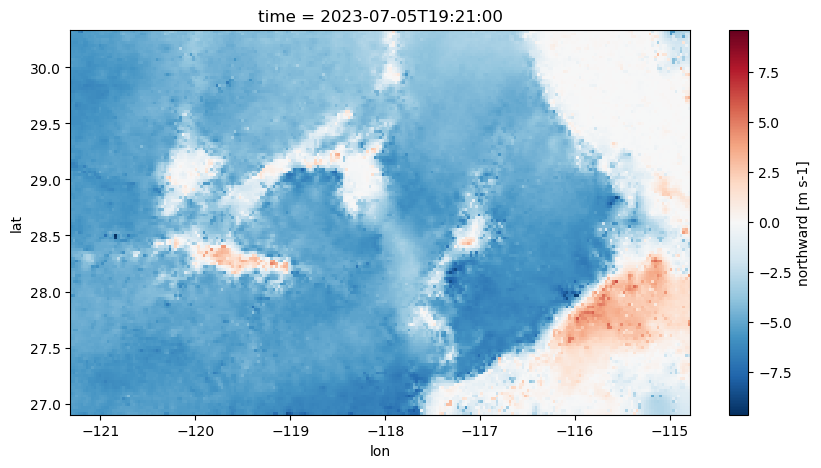

In [64]:
ds_piv.v.plot(size=5,aspect=2);

In [49]:
# ---- PIV settings experiments -> one multi-page PDF (one experiment per page) ------------------
# Each experiment changes ONE thing from the baseline. Colour scales are fixed by the baseline page,
# so pages can be compared by flipping through.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

PDF_PATH = "piv_experiments.pdf" # local
DT = 600.0
VARS = ["u", "v", "div", "vor"]
BASE = dict(windowsizes=(128, 64, 32, 32), overlaps=(64, 32, 16, 16))

# (experiment, what changes from baseline, make_settings changes, piv_to_xarray extras)
EXPERIMENTS = [
    ("A. Baseline", "128-64-32-32, 50% overlap", {}, {}),

    ("B. Final window size", "final window 16 px",
     dict(windowsizes=(128, 64, 32, 16), overlaps=(64, 32, 16, 8)), {}),
    ("B. Final window size", "final window 8 px",
     dict(windowsizes=(128, 64, 32, 16, 8), overlaps=(64, 32, 16, 8, 4)), {}),

    ("C. Final-pass overlap", "32-px windows, 75% overlap",
     dict(overlaps=(64, 32, 16, 24)), {}),
    ("C. Final-pass overlap", "16-px windows, 75% overlap",
     dict(windowsizes=(128, 64, 32, 16), overlaps=(64, 32, 16, 12)), {}),

    ("D. Repeated final pass", "16-px windows, final pass repeated",
     dict(windowsizes=(128, 64, 32, 16, 16), overlaps=(64, 32, 16, 8, 8)), {}),

    ("E. Correlation", "normalized correlation", dict(normalized_correlation=True), {}),

    ("F. Wave rejection: peak2peak", "sig2noise threshold 1.2",
     dict(sig2noise_method="peak2peak", sig2noise_threshold=1.2), {}),
    ("F. Wave rejection: peak2peak", "sig2noise threshold 1.3",
     dict(sig2noise_method="peak2peak", sig2noise_threshold=1.3), {}),
    ("F. Wave rejection: peak2peak", "sig2noise threshold 1.5",
     dict(sig2noise_method="peak2peak", sig2noise_threshold=1.5), {}),

    ("G. Median test", "stricter, 5x5 neighbourhood", dict(median_size=2, median_threshold=2), {}),
    ("G. Median test", "looser (threshold 5)", dict(median_threshold=5), {}),

    ("H. Coarse-pass check", "max deviation 1 px from 128-px pass", {}, dict(ref_pass=0, max_dev_px=1.0)),
    ("H. Coarse-pass check", "max deviation 2 px from 128-px pass", {}, dict(ref_pass=0, max_dev_px=2.0)),
    ("H. Coarse-pass check", "max deviation 4 px from 128-px pass", {}, dict(ref_pass=0, max_dev_px=4.0)),
]

lims = {}
with PdfPages(PDF_PATH) as pdf:
    for n, (group, change, changes, extras) in enumerate(EXPERIMENTS, 1):
        kw = {**BASE, **changes}
        print(f"{n}/{len(EXPERIMENTS)}  {group}: {change}")
        try:
            ds_piv = piv_to_xarray(frame_a, frame_b, dt=DT, settings=make_settings(**kw), **extras)
        except Exception as err:
            print("   failed:", err)
            continue
        fig, axs = plt.subplots(2, 2, figsize=(16, 10), layout="constrained")
        for var, ax in zip(VARS, axs.flat):
            if var not in lims:                       # colour limits taken from the baseline page
                lo, hi = np.nanpercentile(ds_piv[var], [2, 98])
                lims[var] = dict(vmin=lo, vmax=hi) if var in ("u", "v") else dict(vmax=max(-lo, hi), center=0)
            ds_piv[var].plot(ax=ax, rasterized=True, **lims[var])
        other = {k: v for k, v in {**changes, **extras}.items() if k not in ("windowsizes", "overlaps")}
        step = kw["windowsizes"][-1] - kw["overlaps"][-1]
        fig.suptitle(f"Page {n}   {group}:  {change}\n"
                     f"windows {kw['windowsizes']}   overlaps {kw['overlaps']}   step {step} px   "
                     f"grid {ds_piv.u.shape[0]}x{ds_piv.u.shape[1]}   flagged {float(ds_piv.flag.mean()):.1%}"
                     + (f"\n{other}" if other else ""), fontsize=14)
        pdf.savefig(fig, dpi=150)
        plt.close(fig)
print("wrote", PDF_PATH)

1/15  A. Baseline: 128-64-32-32, 50% overlap
2/15  B. Final window size: final window 16 px
3/15  B. Final window size: final window 8 px
4/15  C. Final-pass overlap: 32-px windows, 75% overlap
5/15  C. Final-pass overlap: 16-px windows, 75% overlap
6/15  D. Repeated final pass: 16-px windows, final pass repeated
7/15  E. Correlation: normalized correlation
8/15  F. Wave rejection: peak2peak: sig2noise threshold 1.2
9/15  F. Wave rejection: peak2peak: sig2noise threshold 1.3
10/15  F. Wave rejection: peak2peak: sig2noise threshold 1.5
11/15  G. Median test: stricter, 5x5 neighbourhood
12/15  G. Median test: looser (threshold 5)
13/15  H. Coarse-pass check: max deviation 1 px from 128-px pass
14/15  H. Coarse-pass check: max deviation 2 px from 128-px pass
15/15  H. Coarse-pass check: max deviation 4 px from 128-px pass
wrote /Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/Hanna_outputs/Baja/piv_experiments.pdf


In [65]:
!open piv_experiments.pdf
# opens in preview 

In [91]:
# ---- Browse frame pairs: Tb image + PIV vectors + smoothed divergence contours, one page per pair ----
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

PDF_PATH = "piv_frames.pdf"
N_PAIRS = 54
ST = make_settings(median_size=2, median_threshold=2)      # page 11: stricter median test, 5x5
SKIP = 3                                    # draw every 4th vector in each direction
SMOOTH = 2                                  # divergence smoothing: running mean over SMOOTH x SMOOTH vectors (1 = none)
DIV_LEVELS = np.array([-6, -5, -4, 2, 4, 6]) * 1e-5   # contour levels, s-1 (blue negative, red positive)
VOR_LEVELS = np.array([-25,-15, 15,25]) * 1e-5   # contour levels, s-1 (blue negative, red positive)

with PdfPages(PDF_PATH) as pdf:
    for i in range(min(N_PAIRS, ds.sizes["time"] - 1)):
        fa, fb = ds.Tb.isel(time=i), ds.Tb.isel(time=i + 1)
        dt = float((fb.time - fa.time) / np.timedelta64(1, "s"))
        pv = piv_to_xarray(fa, fb, dt=dt, settings=ST)
        
        div = pv.div.rolling(lat=SMOOTH, lon=SMOOTH, center=True, min_periods=1).mean()
        vor = pv.vor.rolling(lat=SMOOTH, lon=SMOOTH, center=True, min_periods=1).mean()

        fig, ax = plt.subplots(figsize=(19.2, 11.5), layout="constrained")
        fa.plot.imshow(ax=ax, cmap="Greys_r", interpolation="none", add_colorbar=False)
        pv.isel(lat=slice(None, None, SKIP), lon=slice(None, None, SKIP)).plot.quiver(
            x="lon", y="lat", u="u", v="v", ax=ax, color="cyan", alpha=0.7, width=0.0008, add_guide=False)

        #shaded color for div 
        div.plot.imshow(ax=ax, cmap="RdBu_r", alpha=0.5, add_colorbar=False)

        #contours of div and vor 
        # div.plot.contour(ax=ax, levels=DIV_LEVELS, cmap="RdBu_r", linewidths=0.6, add_colorbar=False)
        vor.plot.contour(ax=ax, levels=VOR_LEVELS, cmap="PiYG", linewidths=2, add_colorbar=False)
        
        ax.set_title(f"Pair {i}:  {str(fa.time.values)[:16]}  ->  {str(fb.time.values)[:16]}   "
                     f"dt {dt:.0f} s   flagged {float(pv.flag.mean()):.1%}   "
                     f"div contours {DIV_LEVELS.tolist()} s-1, smoothed {SMOOTH}x{SMOOTH}", fontsize=13)
        pdf.savefig(fig)
        plt.close(fig)
        print(i, end=" ")
print("\nwrote", PDF_PATH)

0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 
wrote piv_frames.pdf


In [92]:
!open piv_frames.pdf

In [88]:
!ls -l piv_frames.pdf

-rw-r--r--@ 1 bmapes  staff  33855503 Nov  6 17:29 piv_frames.pdf


In [85]:
!mv piv_frames.pdf piv_frames_shaded_vor.pdf